In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

import scanpy as sc
import scvi
import pathlib
import warnings
import gc
warnings.filterwarnings('ignore')

sc.set_figure_params(figsize=(4, 4))

[rank: 0] Global seed set to 0


## Data loading

In [3]:
#SCKL = sc.read_h5ad("/work/uv525372/heart_atlas/Heart_SCKL.h5ad")

In [6]:
#König = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/König_2022_raw.h5ad")

In [7]:
#Heart = König.concatenate(SCKL)
#Heart

AnnData object with n_obs × n_vars = 1262283 × 24495
    obs: 'nCount_RNA', 'nFeature_RNA', 'Cell_type', 'Condition', 'n_genes', 'Technology', 'Assay', 'Study', 'Tissue', 'Donor', 'Age', 'Sex', 'BMI', 'Hypertension', 'Diabetes', 'Ischemia', 'Death', 'Doublets', 'n_umi', 'entropy', 'doublet_score', 'Subcluster', 'Genotype', 'SNP', 'batch'
    var: 'name-0', 'n_cells-0', 'gene_id-0', 'feature_types-0-0-1', 'genome-0-0-1', 'n_cells-0-0-1', 'gene_symbol-0-0-1', 'feature_types-1-0-1', 'genome-1-0-1', 'n_cells-1-0-1', 'gene_symbol-1-0-1', 'n_cells-2-0-1', 'gene_symbol-2-0-1', 'feature_name-1-1', 'feature_reference-1-1', 'feature_biotype-1-1'

In [5]:
#Reichart = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Reichart_2022_raw.h5ad")

In [9]:
#Heart = Reichart.concatenate(Heart)

In [11]:
#Heart

AnnData object with n_obs × n_vars = 1855902 × 24441
    obs: 'Tissue', 'nCount_RNA', 'nFeature_RNA', 'Technology', 'Assay', 'Study', 'Sex', 'Donor', 'Age', 'Condition', 'Death', 'BMI', 'Hypertension', 'Diabetes', 'Genotype', 'Doublets', 'Cell_type', 'Subcluster', 'n_genes', 'Ischemia', 'n_umi', 'entropy', 'doublet_score', 'SNP', 'batch'
    var: 'feature_name-0', 'feature_reference-0', 'feature_biotype-0', 'n_cells-0', 'name-0-1', 'n_cells-0-1', 'gene_id-0-1', 'feature_types-0-0-1-1', 'genome-0-0-1-1', 'n_cells-0-0-1-1', 'gene_symbol-0-0-1-1', 'feature_types-1-0-1-1', 'genome-1-0-1-1', 'n_cells-1-0-1-1', 'gene_symbol-1-0-1-1', 'n_cells-2-0-1-1', 'gene_symbol-2-0-1-1', 'feature_name-1-1-1', 'feature_reference-1-1-1', 'feature_biotype-1-1-1'

In [ ]:
#Heart.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Heart_atlas_raw.h5ad")

In [14]:
#Remove doublets from Litvinukova
#Heart = Heart[~Heart.obs.Cell_type.isin(["doublets"])]
#Remove doublets identifed with scDblFinder
#gc.collect()
#Heart = Heart[Heart.obs['Doublets']<2]

In [15]:
#Heart.var.drop(["feature_reference-0", "feature_biotype-0", "feature_types-0-0-1-1", "genome-0-0-1-1", "feature_types-1-0-1-1", "genome-1-0-1-1", "feature_reference-1-1-1", "feature_biotype-1-1-1"], axis=1, inplace=True)
#Heart.var.drop(["feature_name-1-1-1", 'gene_symbol-1-0-1-1'], axis=1, inplace=True)
#Heart.var

,feature_name-0,n_cells-0,name-0-1,n_cells-0-1,gene_id-0-1,n_cells-0-0-1-1,gene_symbol-0-0-1-1,n_cells-1-0-1-1,n_cells-2-0-1-1,gene_symbol-2-0-1-1
ENSG00000238009,RP11-34P13.7,12981,RP11-34P13.7,2383,ENSG00000238009,360,AL627309.1,4463,5454,AL627309.1
ENSG00000229905,RP11-206L10.4,174,RP11-206L10.4,13,ENSG00000229905,20,AL669831.2,224,75,AL669831.2
ENSG00000237491,LINC01409,59693,RP11-206L10.9,13088,ENSG00000237491,6365,LINC01409,66486,28909,AL669831.5
ENSG00000177757,FAM87B,437,FAM87B,227,ENSG00000177757,64,FAM87B,763,314,FAM87B
ENSG00000230368,FAM41C,612,FAM41C,67,ENSG00000230368,15,FAM41C,183,985,FAM41C
...,...,...,...,...,...,...,...,...,...,...
ENSG00000278817,ENSG00000278817.1,9949,AC007325.4,1831,ENSG00000278817,56,AC007325.4,833,7862,AC007325.4
ENSG00000277196,ENSG00000277196.4,2273,AC007325.2,2000,ENSG00000277196,115,AC007325.2,925,1523,AC007325.2
ENSG00000278384,ENSG00000278384.1,17423,AL354822.1,6412,ENSG00000278384,1226,AL354822.1,11957,11767,AL354822.1
ENSG00000276345,ENSG00000276345.1,1291,AC004556.1,966,ENSG00000276345,15,AC004556.3,242,3369,AC004556.1


In [16]:
#Heart

AnnData object with n_obs × n_vars = 1825244 × 24441
    obs: 'Tissue', 'nCount_RNA', 'nFeature_RNA', 'Technology', 'Assay', 'Study', 'Sex', 'Donor', 'Age', 'Condition', 'Death', 'BMI', 'Hypertension', 'Diabetes', 'Genotype', 'Doublets', 'Cell_type', 'Subcluster', 'n_genes', 'Ischemia', 'n_umi', 'entropy', 'doublet_score', 'SNP', 'batch'
    var: 'feature_name-0', 'n_cells-0', 'name-0-1', 'n_cells-0-1', 'gene_id-0-1', 'n_cells-0-0-1-1', 'gene_symbol-0-0-1-1', 'n_cells-1-0-1-1', 'n_cells-2-0-1-1', 'gene_symbol-2-0-1-1'

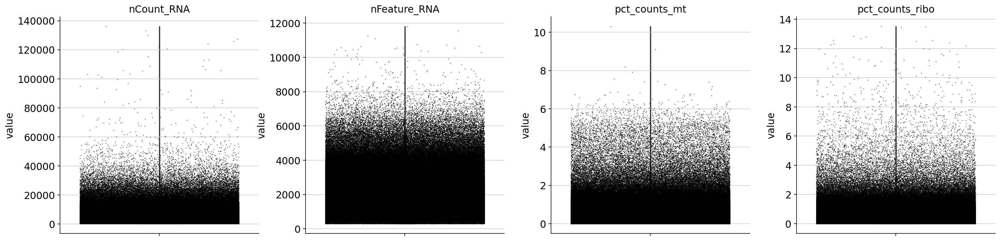

In [17]:
#Heart.var['mt'] = Heart.var["feature_name-0"].str.startswith('MT-')
#sc.pp.calculate_qc_metrics(Heart, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
#Heart.var['ribo'] = Heart.var["feature_name-0"].str.startswith(("RPS","RPL"))
#sc.pp.calculate_qc_metrics(Heart, qc_vars=['ribo'], percent_top=None, log1p=False, inplace=True)
#sc.pl.violin(Heart, ['nCount_RNA', 'nFeature_RNA', 'pct_counts_mt', 'pct_counts_ribo'],jitter=0.4, multi_panel=True)
#Heart = Heart[Heart.obs.pct_counts_mt < 5, :]
#Heart = Heart[Heart.obs.pct_counts_ribo < 5, :]

In [18]:
#Heart.obs.to_csv("Heart_atlas_meta_data.csv")

In [19]:
#Heart.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Heart_atlas_raw.h5ad")

In [20]:
#Heart

View of AnnData object with n_obs × n_vars = 1822667 × 24441
    obs: 'Tissue', 'nCount_RNA', 'nFeature_RNA', 'Technology', 'Assay', 'Study', 'Sex', 'Donor', 'Age', 'Condition', 'Death', 'BMI', 'Hypertension', 'Diabetes', 'Genotype', 'Doublets', 'Cell_type', 'Subcluster', 'n_genes', 'Ischemia', 'n_umi', 'entropy', 'doublet_score', 'SNP', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'feature_name-0', 'n_cells-0', 'name-0-1', 'n_cells-0-1', 'gene_id-0-1', 'n_cells-0-0-1-1', 'gene_symbol-0-0-1-1', 'n_cells-1-0-1-1', 'n_cells-2-0-1-1', 'gene_symbol-2-0-1-1', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'

In [5]:
#Heart = Heart[Heart.obs["Donor"] != "H84"]
#Heart = Heart[Heart.obs["Donor"] != "IC_H04"]
#Heart = Heart[Heart.obs["Donor"] != "IC_H03"]
#Heart = Heart[Heart.obs["Donor"] != "DO1"]

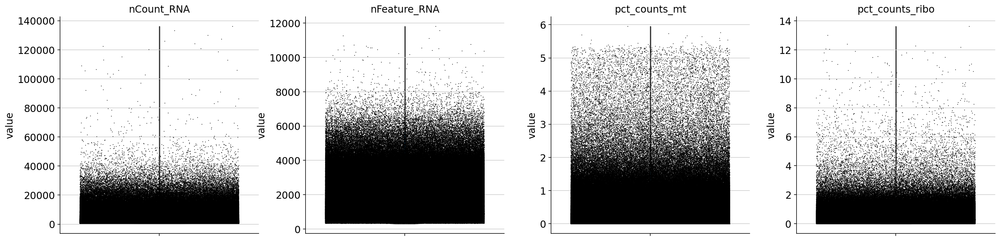

In [3]:
#sc.pp.filter_cells(Heart, min_genes=300)
#sc.pp.filter_genes(Heart, min_cells=5)
#Heart.var['mt'] = Heart.var_names.str.startswith('MT-')
#sc.pp.calculate_qc_metrics(Heart, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
#Heart.var['ribo'] = Heart.var_names.str.startswith(("RPS","RPL"))
#sc.pp.calculate_qc_metrics(Heart, qc_vars=['ribo'], percent_top=None, log1p=False, inplace=True)
#sc.pl.violin(Heart, ['nCount_RNA', 'nFeature_RNA', 'pct_counts_mt', 'pct_counts_ribo'],jitter=0.4, multi_panel=True)
#Heart = Heart[Heart.obs.pct_counts_mt < 4, :]
#Heart = Heart[Heart.obs.pct_counts_ribo < 4, :]

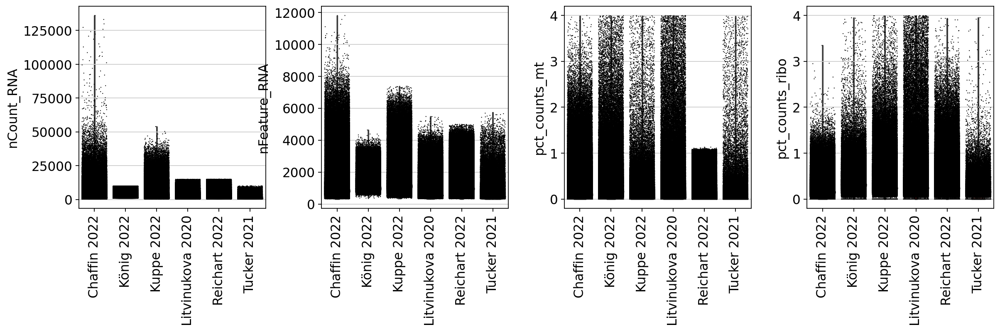

In [14]:
#sc.pl.violin(Heart, ['nCount_RNA', 'nFeature_RNA', 'pct_counts_mt', 'pct_counts_ribo'], groupby="Study", rotation=90, jitter=0.4, multi_panel=True)

In [2]:
#Heart = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Heart_atlas_raw.h5ad")

In [3]:
#gc.collect()
#Heart

AnnData object with n_obs × n_vars = 1822667 × 24441
    obs: 'Tissue', 'nCount_RNA', 'nFeature_RNA', 'Technology', 'Assay', 'Study', 'Sex', 'Donor', 'Age', 'Condition', 'Death', 'BMI', 'Hypertension', 'Diabetes', 'Genotype', 'Doublets', 'Cell_type', 'Subcluster', 'n_genes', 'Ischemia', 'n_umi', 'entropy', 'doublet_score', 'SNP', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'feature_name-0', 'n_cells-0', 'name-0-1', 'n_cells-0-1', 'gene_id-0-1', 'n_cells-0-0-1-1', 'gene_symbol-0-0-1-1', 'n_cells-1-0-1-1', 'n_cells-2-0-1-1', 'gene_symbol-2-0-1-1', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'

In [4]:
#gc.collect()
#Heart.raw = Heart
#Heart.layers["counts"] = Heart.X.copy()

In [5]:
#gc.collect()
#sc.pp.highly_variable_genes(
#    Heart,
#    flavor="seurat_v3",
#    n_top_genes=5000,
#    layer="counts",
#    batch_key="Donor",
#    subset=True,
#    span=1)

In [6]:
#Heart.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Heart_atlas_raw.h5ad")

In [3]:
#Heart = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Heart_atlas_raws.h5ad")

In [8]:
#sc.pp.normalize_total(Heart, target_sum=1e4)
#gc.collect()
#sc.pp.log1p(Heart)

In [9]:
#gc.collect()
#sc.pp.scale(Heart, max_value=10)

In [14]:
#Heart.write("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Heart_atlas_raw.h5ad")

In [2]:
Heart = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/Heart_atlas_raw.h5ad")

In [13]:
#gc.collect()
#sc.tl.pca(Heart, svd_solver='arpack')

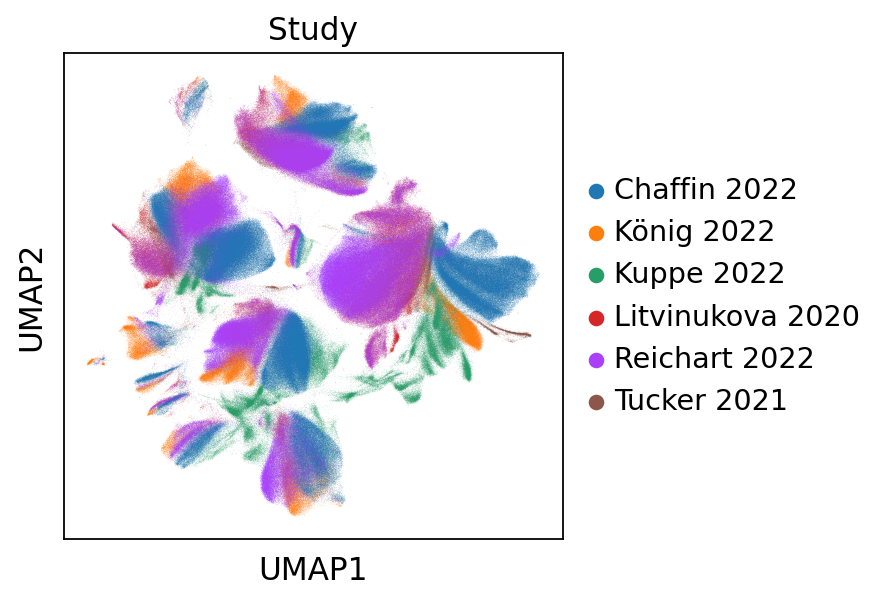

In [14]:
#sc.pp.neighbors(Heart, n_neighbors=10, n_pcs=40)
#sc.tl.umap(Heart)
#sc.pl.umap(Heart, color=['Study'])

In [15]:
scvi.model.SCVI.setup_anndata(Heart, layer="counts", batch_key="Donor")
vaeH = scvi.model.SCVI(Heart, n_layers=2, n_latent=30, gene_likelihood="nb")

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [8]:
vaeH.train()

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 5/5: 100%|██████████| 5/5 [10:28<00:00, 125.64s/it, loss=2.26e+03, v_num=1]


In [9]:
gc.collect()
Heart.obsm["X_scVI"] = vaeH.get_latent_representation()
sc.pp.neighbors(Heart, use_rep="X_scVI")

In [14]:
gc.collect()
sc.tl.umap(Heart)

In [4]:
gc.collect()
sc.tl.leiden(Heart, resolution=0.2, key_added="leiden02")
sc.tl.leiden(Heart, resolution=0.3, key_added="leiden03")
sc.tl.leiden(Heart, resolution=0.4, key_added="leiden04")

In [ ]:
Heart.write('/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/scVI_Heart_atlas.h5ad')
vaeH.save("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/scVI_vaeH")

In [2]:
Heart = sc.read_h5ad('/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/scVI_Heart_atlas.h5ad')

In [3]:
scvi.model.SCVI.setup_anndata(Heart, layer="counts", batch_key="Donor")
vaeH = scvi.model.SCVI(Heart)
vaeH = vaeH.load("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/scVI_vaeH", Heart)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


INFO     File /rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/scVI_vaeH/model.pt already         
         downloaded                                                                                                


In [ ]:
Heart.layers["scvi_normalized"] = vaeH.get_normalized_expression()

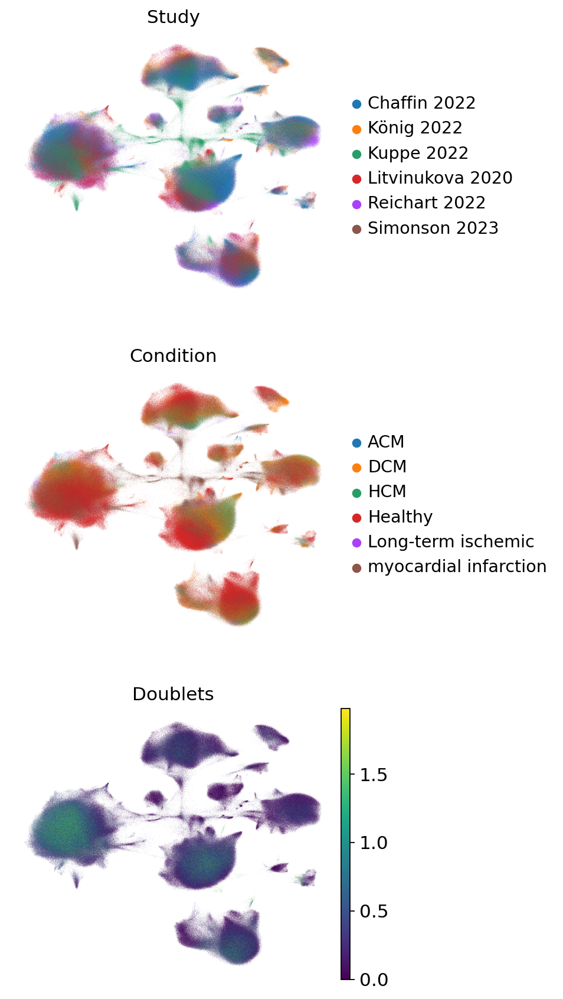

In [7]:
sc.pl.umap(
    Heart, color=["Study", "Condition", "Doublets"], frameon=False, ncols=1,)

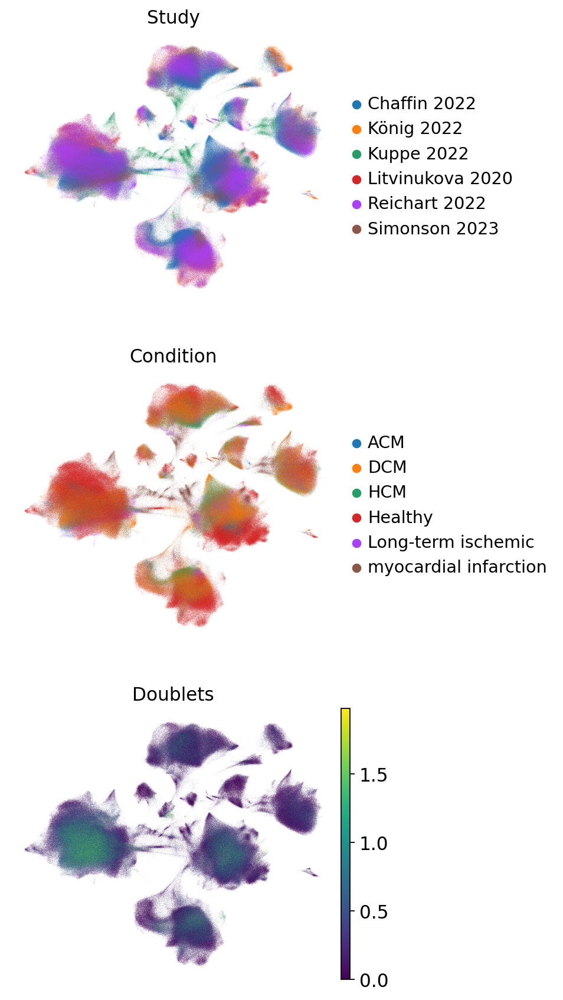

In [5]:
sc.pl.umap(
    Heart, color=["Study", "Condition", "Doublets"], frameon=False, ncols=1,)

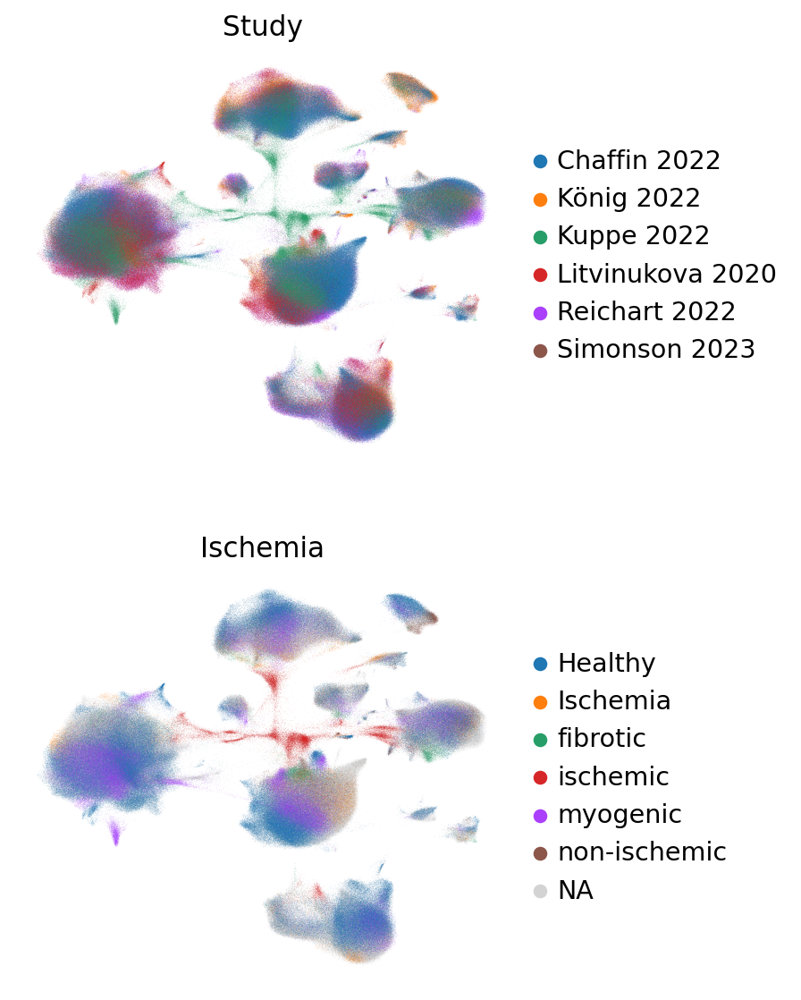

In [7]:
sc.pl.umap(
    Heart,
    color=["Study", "Ischemia"],
   frameon=False,
   ncols=1,)

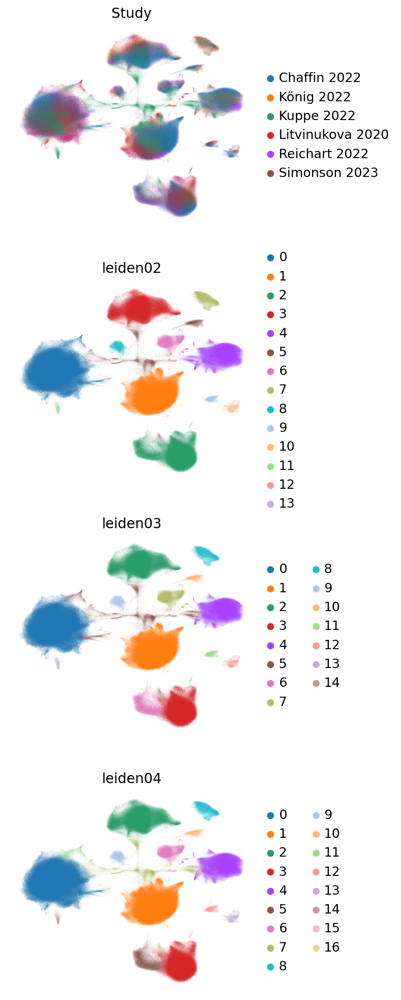

In [9]:
#sub =Heart[Heart.obs["Study"] == "Chaffin 2022"]
sc.pl.umap(
    Heart,
    color=["Study", "leiden02", "leiden03", "leiden04"],
   frameon=False,
    ncols=1,)

In [13]:
DE_Leiden = vaeH.differential_expression(groupby="leiden04")

DE...: 100%|██████████| 17/17 [14:44<00:00, 52.01s/it]


In [14]:
DE_Leiden['Gene'] = Heart.var["gene_symbol-2-0-1-1"]
DE_Heart = DE_Leiden.set_index('Gene')

In [27]:
Heart.var["Ensembl_ID"] = Heart.var_names
Heart.var.set_index('gene_symbol-2-0-1-1', drop=True, inplace=True)
Heart.var

,feature_name-0,n_cells-0,name-0-1,n_cells-0-1,gene_id-0-1,n_cells-0-0-1-1,gene_symbol-0-0-1-1,n_cells-1-0-1-1,n_cells-2-0-1-1,mt,...,ribo,highly_variable,highly_variable_rank,means,variances,variances_norm,highly_variable_nbatches,mean,std,Ensembl_ID
gene_symbol-2-0-1-1,,,,,,,,,,,,,,,,,,,,,
TNFRSF18,TNFRSF18,569,TNFRSF18,260,ENSG00000186891,25,TNFRSF18,173,2191,False,...,False,True,2022.0,0.000707,0.000949,0.919991,53,0.002106,0.085515,ENSG00000186891
TNFRSF4,TNFRSF4,6433,TNFRSF4,3648,ENSG00000186827,147,TNFRSF4,1824,15374,False,...,False,True,2290.0,0.008689,0.012150,1.155885,113,0.023456,0.275952,ENSG00000186827
FNDC10,FNDC10,396,C1orf233,145,ENSG00000228594,12,FNDC10,110,289,False,...,False,True,2349.0,0.000494,0.000500,0.829641,6,0.001153,0.054993,ENSG00000228594
CDK11B,CDK11B,55007,CDK11B,18700,ENSG00000248333,4123,CDK11B,32269,35819,False,...,False,True,2333.0,0.079877,0.093409,0.852652,2,0.170668,0.658332,ENSG00000248333
SLC35E2B,SLC35E2B,55732,SLC35E2B,29594,ENSG00000189339,3439,SLC35E2B,36685,23420,False,...,False,True,222.0,0.087063,0.097733,0.820050,1,0.185496,0.680094,ENSG00000189339
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-CO3,MT-CO3,272729,MT-CO3,140627,ENSG00000198938,9937,MT-CO3,24548,282495,True,...,False,True,1156.5,0.845143,2.517408,0.994360,74,1.350537,1.640855,ENSG00000198938
MT-ND3,MT-ND3,126860,MT-ND3,99947,ENSG00000198840,4369,MT-ND3,11383,205312,True,...,False,True,1875.0,0.428861,0.799653,0.909954,64,0.827040,1.401667,ENSG00000198840
MT-ND4,MT-ND4,105034,MT-ND4,72862,ENSG00000198886,7759,MT-ND4,11391,208143,True,...,False,True,1908.5,0.383784,0.726570,0.967881,70,0.746475,1.346331,ENSG00000198886


In [15]:
markers = {}
cats = Heart.obs.leiden04.cat.categories
for i, c in enumerate(cats):
    cid = "{} vs Rest".format(c)
    C_scANVI_df = DE_Heart.loc[DE_Heart.comparison == cid]
    
    C_scANVI_df = C_scANVI_df.sort_values("lfc_mean", ascending=False)
    C_scANVI_df = C_scANVI_df[C_scANVI_df.lfc_mean > 0]

    C_scANVI_df = C_scANVI_df[C_scANVI_df["bayes_factor"] > 3]
    C_scANVI_df = C_scANVI_df[C_scANVI_df["non_zeros_proportion1"] > 0.1]

    markers[c] = C_scANVI_df.index.tolist()[:7]

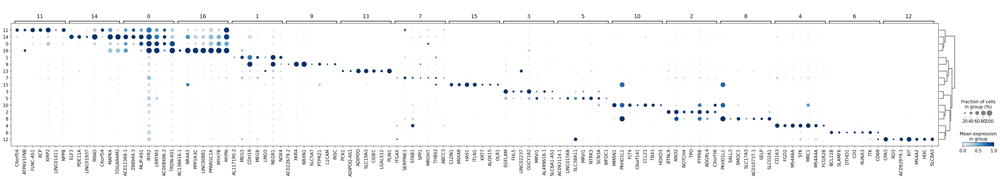

In [16]:
sc.tl.dendrogram(Heart, groupby="leiden04", use_rep="X_scVI")
sc.pl.dotplot(
    Heart,
    markers,
    groupby='leiden04',
    dendrogram=True,
    color_map="Blues",
    use_raw=False,
    gene_symbols='gene_symbol-2-0-1-1',
    #layer="scvi_normalized",
    standard_scale="var",)

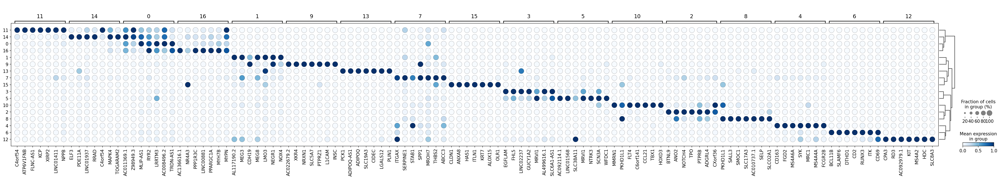

In [37]:
sc.tl.dendrogram(Heart, groupby="leiden04", use_rep="X_scVI")
sc.pl.dotplot(
    Heart,
    markers,
    groupby='leiden04',
    dendrogram=True,
    color_map="Blues",
    use_raw=False,
    gene_symbols='gene_symbol-2-0-1-1',
    layer="scvi_normalized",
    #expression_cutoff =0.1,
    standard_scale="var",)

In [45]:
cell_dict = {'Cardiomyocytes': ['0', '11', '14', '16'], 'Fibroblast': ['1'], 'Endothelial': ['2'], 'Pericytes':["3"],
             'Monocytes': ['4'], 'VSMC': ['5'], 'Lymphocytes': ['6'],'Ischemic cells (MI)':['7'], 'Endocardial':['8'], 'Neuronal':['9'], 
             'Lymphatic EC':['10'], 'Mast cells':['12'], 'Adipocytes':['13'], 'Epicardium':['15']}
Heart.obs['Annotation_1'] = np.nan
for i in cell_dict.keys():
    ind = pd.Series(Heart.obs.leiden04).isin(cell_dict[i])
    Heart.obs.loc[ind,'Annotation_1'] = i

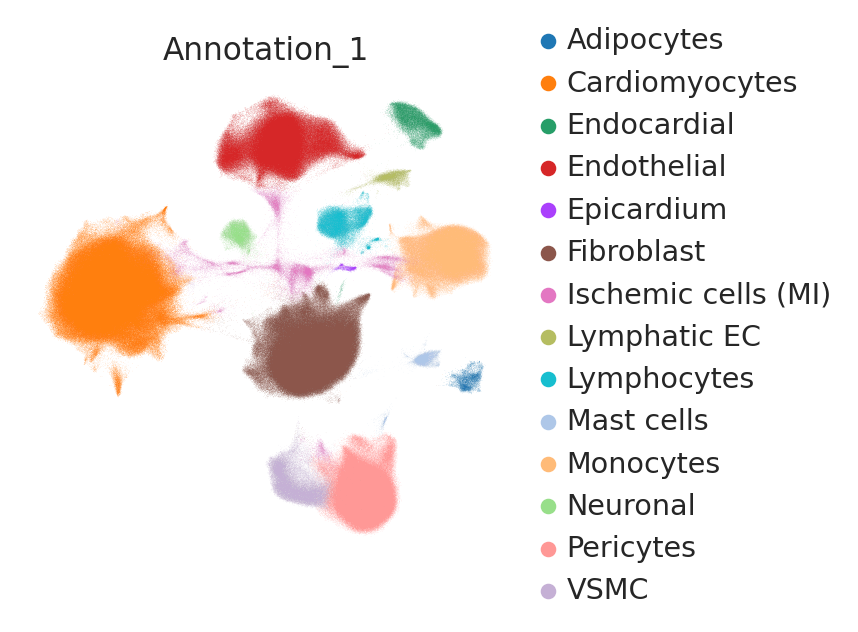

In [46]:
sc.pl.umap(
    Heart,
    color=["Annotation_1"],
    frameon=False,
    ncols=1,)

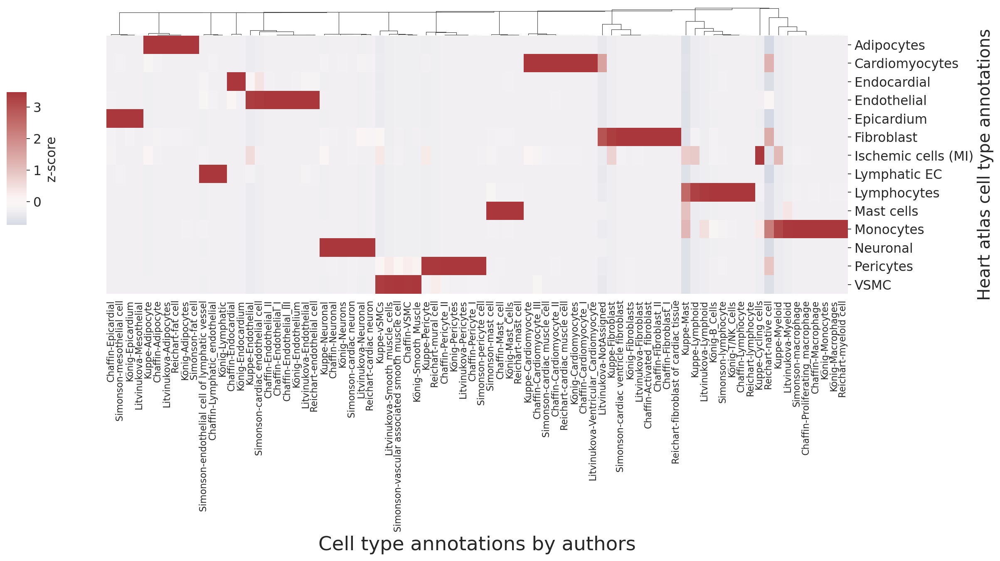

In [47]:
Heart.obs['celltype_batch'] = np.char.add(np.char.add(np.array(Heart.obs['Study'].str.split().str.get(0), dtype= str), '-'),
                                             np.array(Heart.obs['Cell_type'], dtype=str))
df = Heart.obs.groupby(["celltype_batch", "Annotation_1"]).size().unstack(fill_value=0)
import matplotlib.cm as cm
sns.set_style("whitegrid", {'axes.grid' : False})

g = sns.clustermap(df.transpose(), row_cluster=False, z_score=1, cmap="vlag", center=0, method='centroid', dendrogram_ratio=0.1, cbar_pos=(-0.001, 0.65, 0.02, 0.2), xticklabels=True, figsize=(15, 10))

g.ax_cbar.set_ylabel("z-score")
g.ax_heatmap.set_ylabel('Heart atlas cell type annotations', fontsize = 18)
g.ax_heatmap.set_xlabel('Cell type annotations by authors', fontsize = 21)

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xmajorticklabels(), fontsize = 10)
plt.show()

